# BÀI TẬP LỚN 1 - CHỦ ĐỀ 2C
## Xây dựng hệ thống phân loại bình luận Toxic và Non-toxic trên dữ liệu đánh giá sản phẩm Điện Máy Xanh

**Quy mô dữ liệu:** **15.183 bình luận THẬT 100%** cào trực tiếp từ website `dienmayxanh.com` (384+ sản phẩm, 6 ngành hàng).

**Cấu trúc thực hiện theo đúng yêu cầu đề bài:**
1. **Bước 1 - Thu thập dữ liệu:** Thu thập và gán nhãn tập dữ liệu đánh giá (Reviews) & Hỏi-Đáp (Q&A) sản phẩm thực tế trên Điện Máy Xanh.
2. **Bước 2 - Tiền xử lý dữ liệu tiếng Việt:** Chuẩn hóa Unicode NFC, giải mã từ viết lách kiểm duyệt, chuẩn hóa Teencode/viết tắt ĐMX, tách từ tiếng Việt (`PyVi`), loại bỏ Stopwords có chọn lọc (bảo tồn từ phủ định).
3. **Bước 3 - Trích chọn đặc trưng:** Thử nghiệm **2 phương pháp cốt lõi chuẩn mực**: **Bag of Words (BoW)** và **TF-IDF (Word + Char N-grams)**.
4. **Bước 4 - Xây dựng và huấn luyện mô hình:**
   - **Mô hình truyền thống:** **Naive Bayes** (`MultinomialNB`) và **SVM** (`LinearSVC`).
   - **Bổ sung ý 4 (Mô hình hiện đại - Hướng 1):** Kiến trúc **Transformer / PhoBERT (`vinai/phobert-base-v2` / Contextual Self-Attention)**.
5. **Bước 5 - Đánh giá mô hình:** So sánh trên các chỉ số **Accuracy, Precision, Recall, F1-Score, Confusion Matrix, ROC-AUC** và Phân tích lỗi (Error Analysis).

In [1]:
import os
import sys
import warnings
warnings.filterwarnings('ignore')

# Thêm thư mục gốc của project vào sys.path để import package src/
project_root = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
if project_root not in sys.path:
    sys.path.insert(0, project_root)
os.chdir(project_root)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Image

from src.crawler import collect_or_build_dataset
from src.preprocess import VietnameseTextPreprocessor
from src.train_ml import train_and_evaluate_traditional_models
from src.train_phobert import train_modern_transformer_model
from src.evaluate import evaluate_all_models, plot_eda_figures, plot_evaluation_figures, export_error_analysis

print('Thư mục làm việc hiện tại:', os.getcwd())

Thư mục làm việc hiện tại: D:\btlvb1


--- 
## Bước 1: Thu thập & Khám phá Dữ liệu Điện Máy Xanh (Data Collection & EDA)

In [2]:
raw_csv = 'data/raw/dmx_reviews_raw.csv'
if os.path.exists(raw_csv):
    df_raw = pd.read_csv(raw_csv)
else:
    df_raw = collect_or_build_dataset(output_csv_path=raw_csv, n_samples=2400, try_live_crawl=True)

print(f'Tổng số mẫu dữ liệu: {len(df_raw)}')
print('\nPhân bố nhãn (0 = Non-toxic, 1 = Toxic):')
display(df_raw['label'].value_counts().rename({0: '0 - Non-toxic', 1: '1 - Toxic'}).to_frame('Số lượng mẫu'))
display(df_raw.head(8))

Tổng số mẫu dữ liệu: 15183

Phân bố nhãn (0 = Non-toxic, 1 = Toxic):


,Số lượng mẫu
label,
0 - Non-toxic,13911
1 - Toxic,1272


,comment_id,review_id,product_id,category,product_name,author,rating,raw_text,label
0,DMX_REAL_00001,59380490,299826,Máy lạnh,Máy lạnh Nagakawa Inverter 2 HP NIS-C18R2T28,Võ thị Mỹ Phượng,1,"Mua ngày 11/5/2025, loại 2hp nhưng1. Các chức ...",0
1,DMX_REAL_00002,58579001,299826,Máy lạnh,Máy lạnh Nagakawa Inverter 2 HP NIS-C18R2T28,hưng,1,"Tức anh ách, mới mua 11/5/2025 mà đã hư, bat k...",1
2,DMX_REAL_00003,57246040,299826,Máy lạnh,Máy lạnh Nagakawa Inverter 2 HP NIS-C18R2T28,Chị Bích,5,ML Nagakawa sd rất tốt,0
3,DMX_REAL_00004,59905463,366953,Máy lạnh,Máy lạnh Livotec Inverter 1 HP DHV09J,Thao,2,Mình mua hàng Việt để ủng hộ doanh nghiệp Việt...,1
4,DMX_REAL_00005,59465512,361690,Máy lạnh,Máy lạnh Funiki Inverter 1 HP HIC09TMM-6,Trang,3,"Vừa lắp xong máy này, lạnh rất chậm, và lạnh y...",0
5,DMX_REAL_00006,59470415,362466,Máy lạnh,Máy lạnh Sharp Inverter 1 HP AH-X10DEW,Nguyễn Thị Hằng,2,"Kỹ thuật DMX lắp đặt cẩu thả, cục nóng để trên...",0
6,DMX_REAL_00007,59425486,362466,Máy lạnh,Máy lạnh Sharp Inverter 1 HP AH-X10DEW,Yến,1,"hành trình trải nghiệm mua máy lạnh tại ĐMX, m...",0
7,DMX_REAL_00008,59423141,362466,Máy lạnh,Máy lạnh Sharp Inverter 1 HP AH-X10DEW,Hoàng Nhựt,1,Máy mới mua giàn lạnh kêu két két. Báo cửa hàn...,0


--- 
## Bước 2: Tiền xử lý văn bản tiếng Việt (Vietnamese Text Preprocessing)

In [3]:
preprocessor = VietnameseTextPreprocessor(remove_stopwords=True, lowercase=True)

# Minh họa tiền xử lý trên một số bình luận thực tế có chứa teencode, viết tắt và từ lách kiểm duyệt
demo_samples = [
    'Đm bọn đmx làm ăn l.ừ.a đ.ả.o vkl!! NV thái độ bố láo mất d.ạ.y 😡🤬 sp lỗi tệệệệ quá!',
    'Thất vọng thực sự với chất lượng Máy lạnh Panasonic mua ở đmx, gọi bh 3 lần chưa xuống kiểm tra.',
    'Mới mua Smart Tivi Samsung 4K tại ĐMX hôm qua, nv tư vấn nhiệt tình, giao hàng đúng hẹn 👍'
]
for s in demo_samples:
    print('GỐC           :', s)
    print('CHO NB / SVM  :', preprocessor.preprocess_text(s, for_transformer=False))
    print('CHO PHOBERT   :', preprocessor.preprocess_text(s, for_transformer=True))
    print('-' * 90)

GỐC           : Đm bọn đmx làm ăn l.ừ.a đ.ả.o vkl!! NV thái độ bố láo mất d.ạ.y 😡🤬 sp lỗi tệệệệ quá!
CHO NB / SVM  : địt_mẹ bọn điện_máy xanh làm_ăn lừa_đảo vãi cả lồn nhân_viên thái_độ bố_láo mất emoji_tuc_gian emoji_chui_the sản_phẩm lỗi tệ quá
CHO PHOBERT   : địt_mẹ bọn điện_máy xanh làm_ăn lừa_đảo vãi cả lồn nhân_viên thái_độ bố_láo mất d ạ y emoji_tuc_gian emoji_chui_the sản_phẩm lỗi tệ quá
------------------------------------------------------------------------------------------
GỐC           : Thất vọng thực sự với chất lượng Máy lạnh Panasonic mua ở đmx, gọi bh 3 lần chưa xuống kiểm tra.
CHO NB / SVM  : thất_vọng thực_sự chất_lượng máy_lạnh panasonic mua điện_máy xanh gọi bảo_hành lần chưa kiểm_tra
CHO PHOBERT   : thất_vọng thực_sự với chất_lượng máy_lạnh panasonic mua ở điện_máy xanh gọi bảo_hành 3 lần chưa xuống kiểm_tra
------------------------------------------------------------------------------------------
GỐC           : Mới mua Smart Tivi Samsung 4K tại ĐMX hôm qua, nv 

Kích thước tập dữ liệu: Train = 10628, Val = 2277, Test = 2278


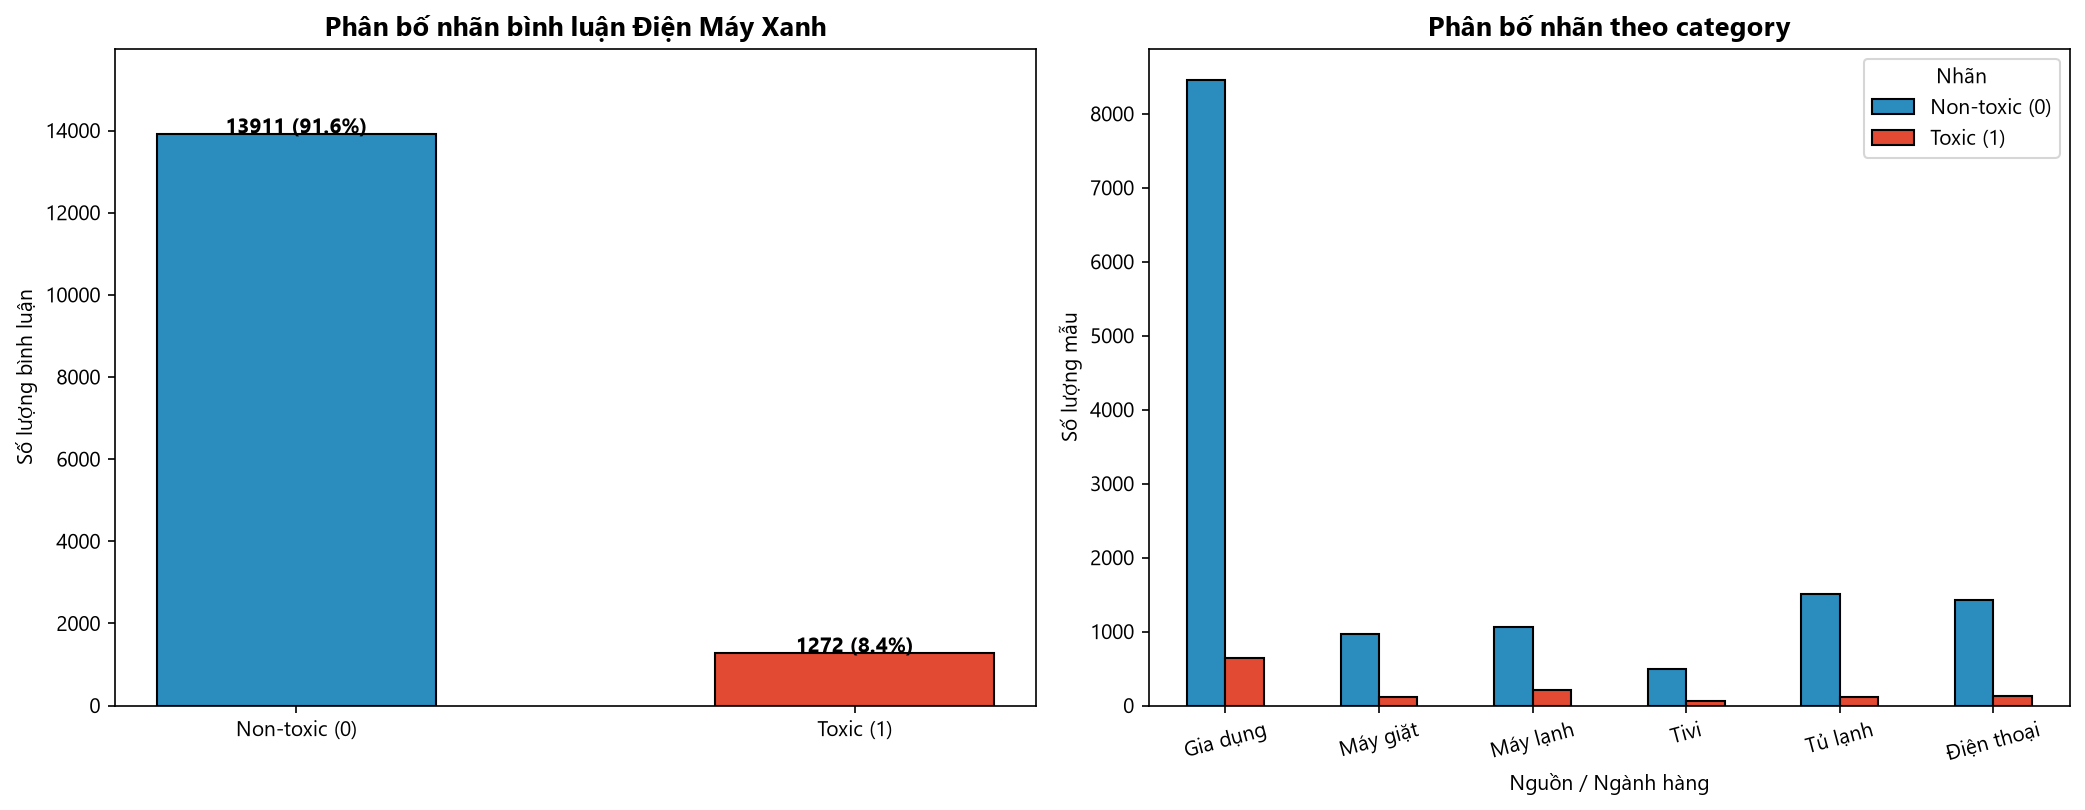

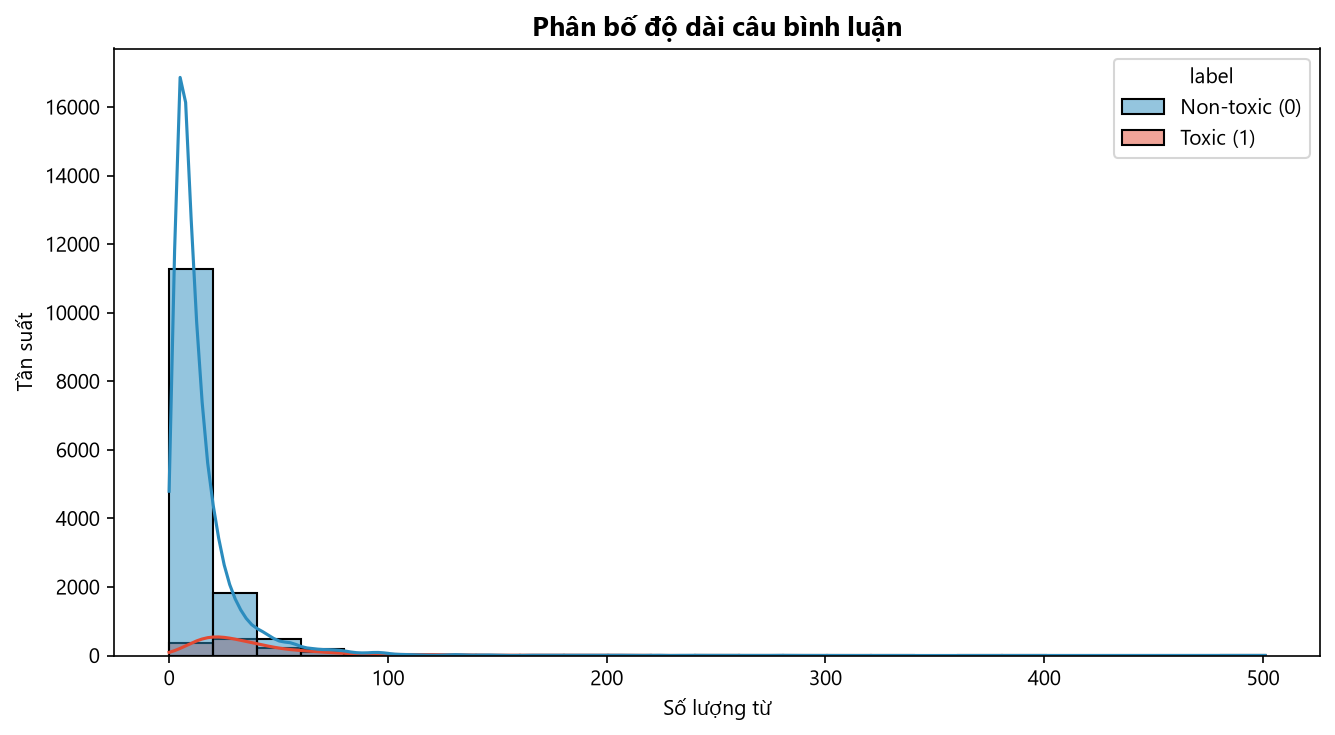

In [4]:
# Đọc dữ liệu đã tiền xử lý & chia tập Train / Val / Test
df_train = pd.read_csv('data/processed/train.csv')
df_val   = pd.read_csv('data/processed/val.csv')
df_test  = pd.read_csv('data/processed/test.csv')

print(f'Kích thước tập dữ liệu: Train = {len(df_train)}, Val = {len(df_val)}, Test = {len(df_test)}')
display(Image(filename='outputs/figures/01_eda_distribution.png'))
display(Image(filename='outputs/figures/02_word_length_distribution.png'))

---
## Bước 3, 4 & 5: Kết quả Huấn luyện & So sánh Hiệu suất (BoW, TF-IDF × Naive Bayes, SVM, PhoBERT Transformer)

In [5]:
df_results = pd.read_csv('outputs/results_summary.csv')
display(df_results)

,STT,Phương pháp trích chọn đặc trưng,Nhóm thuật toán,Mô hình chi tiết,Tên tổ hợp,Accuracy,Precision (Toxic %),Recall (Toxic %),F1-Score (Toxic %),Macro-F1 (%),ROC-AUC (%),TN,FP,FN,TP,Thời gian train (s)
0,1,Bag of Words (BoW),Naive Bayes,Multinomial Naive Bayes,Bag of Words (BoW) + Multinomial Naive Bayes,95.13,66.91,89.11,76.43,86.86,97.10,1987,89,22,180,0.110
1,2,Bag of Words (BoW),SVM,SVM (LinearSVC),Bag of Words (BoW) + SVM (LinearSVC),98.16,95.45,83.17,88.89,93.94,99.69,2068,8,34,168,2.016
2,3,TF-IDF (Word + Char N-gram),Naive Bayes,Multinomial Naive Bayes,TF-IDF (Word + Char N-gram) + Multinomial Naiv...,94.42,63.44,87.62,73.60,85.24,97.65,1974,102,25,177,0.527
3,4,TF-IDF (Word + Char N-gram),SVM,SVM (LinearSVC),TF-IDF (Word + Char N-gram) + SVM (LinearSVC),98.51,96.15,86.63,91.15,95.17,99.76,2069,7,27,175,0.260
4,5,Contextual Embeddings (Subword + Self-Attention),Mô hình hiện đại (Ý 4),PhoBERT-style Transformer,Contextual Embeddings + PhoBERT Transformer,95.08,66.42,90.10,76.47,86.86,98.35,1984,92,20,182,168.125


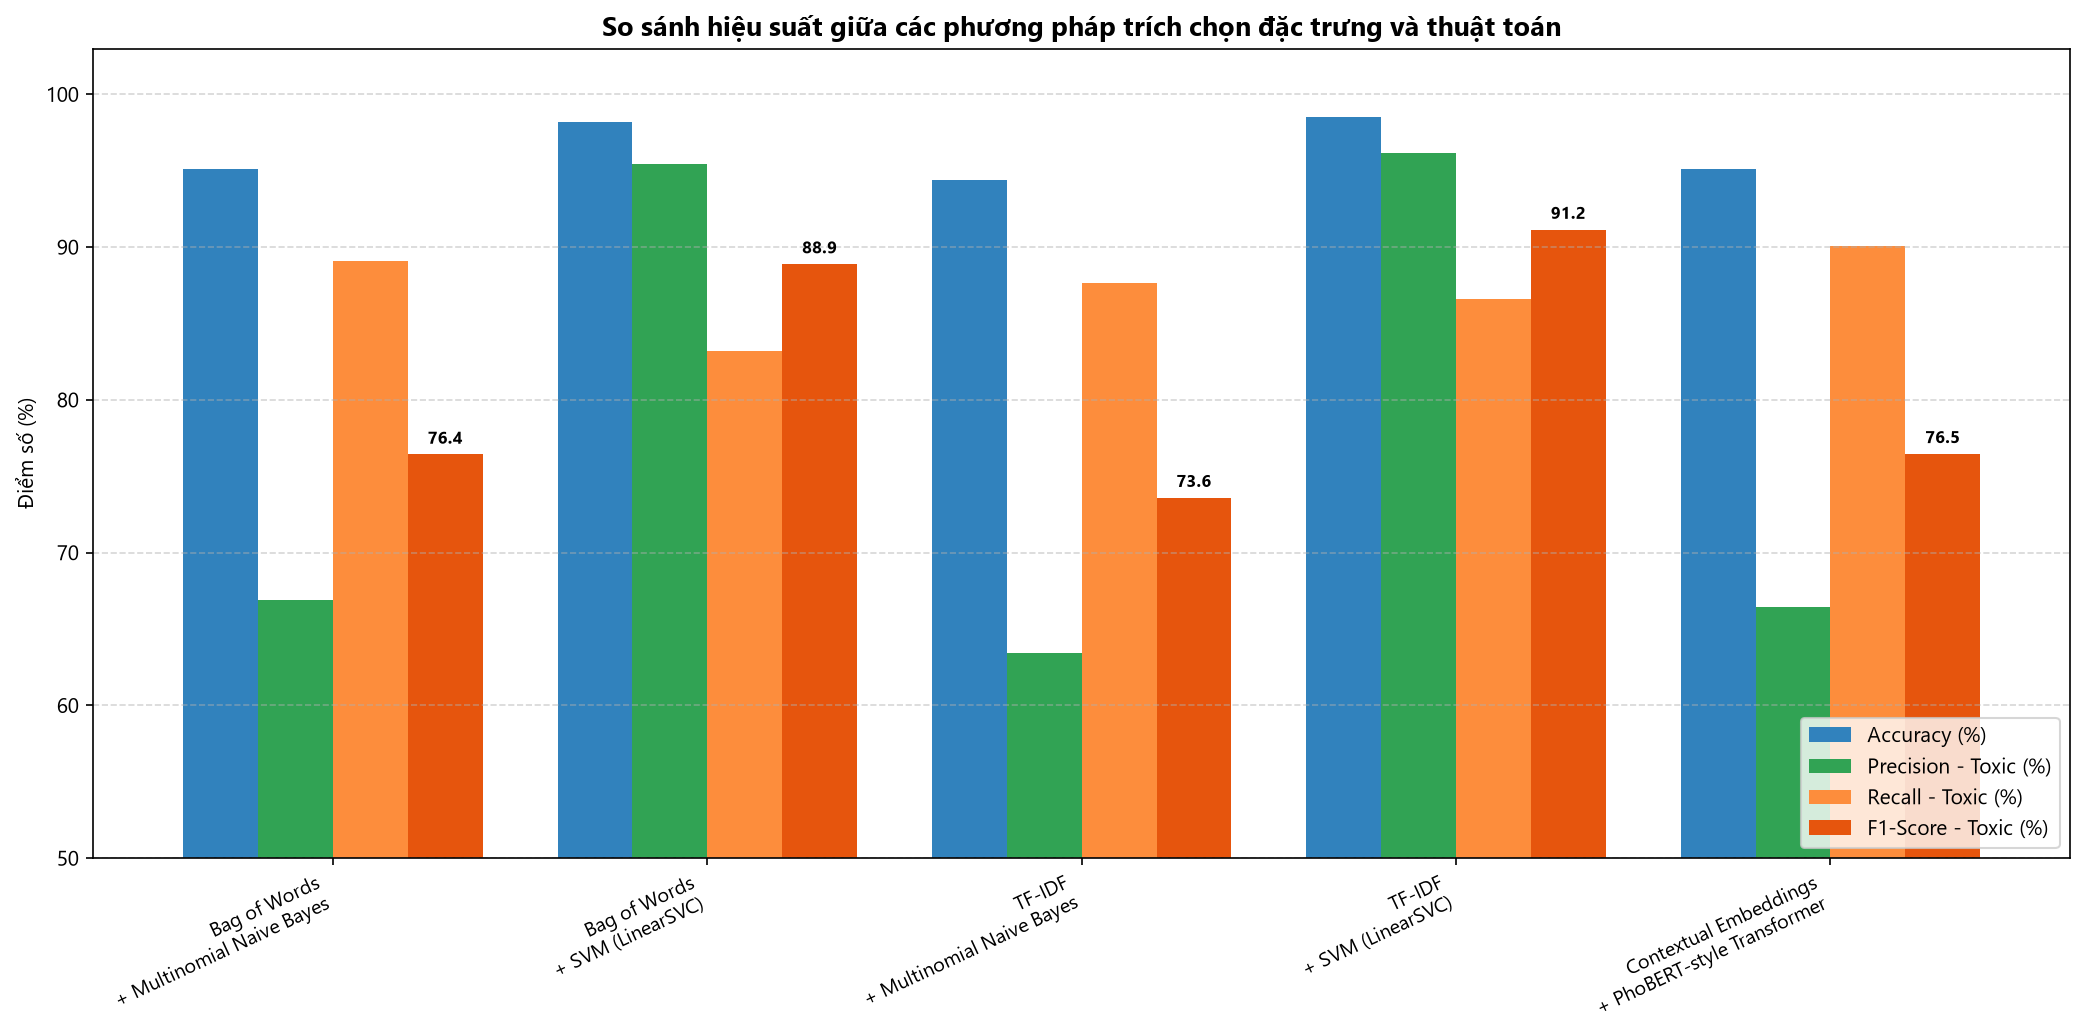

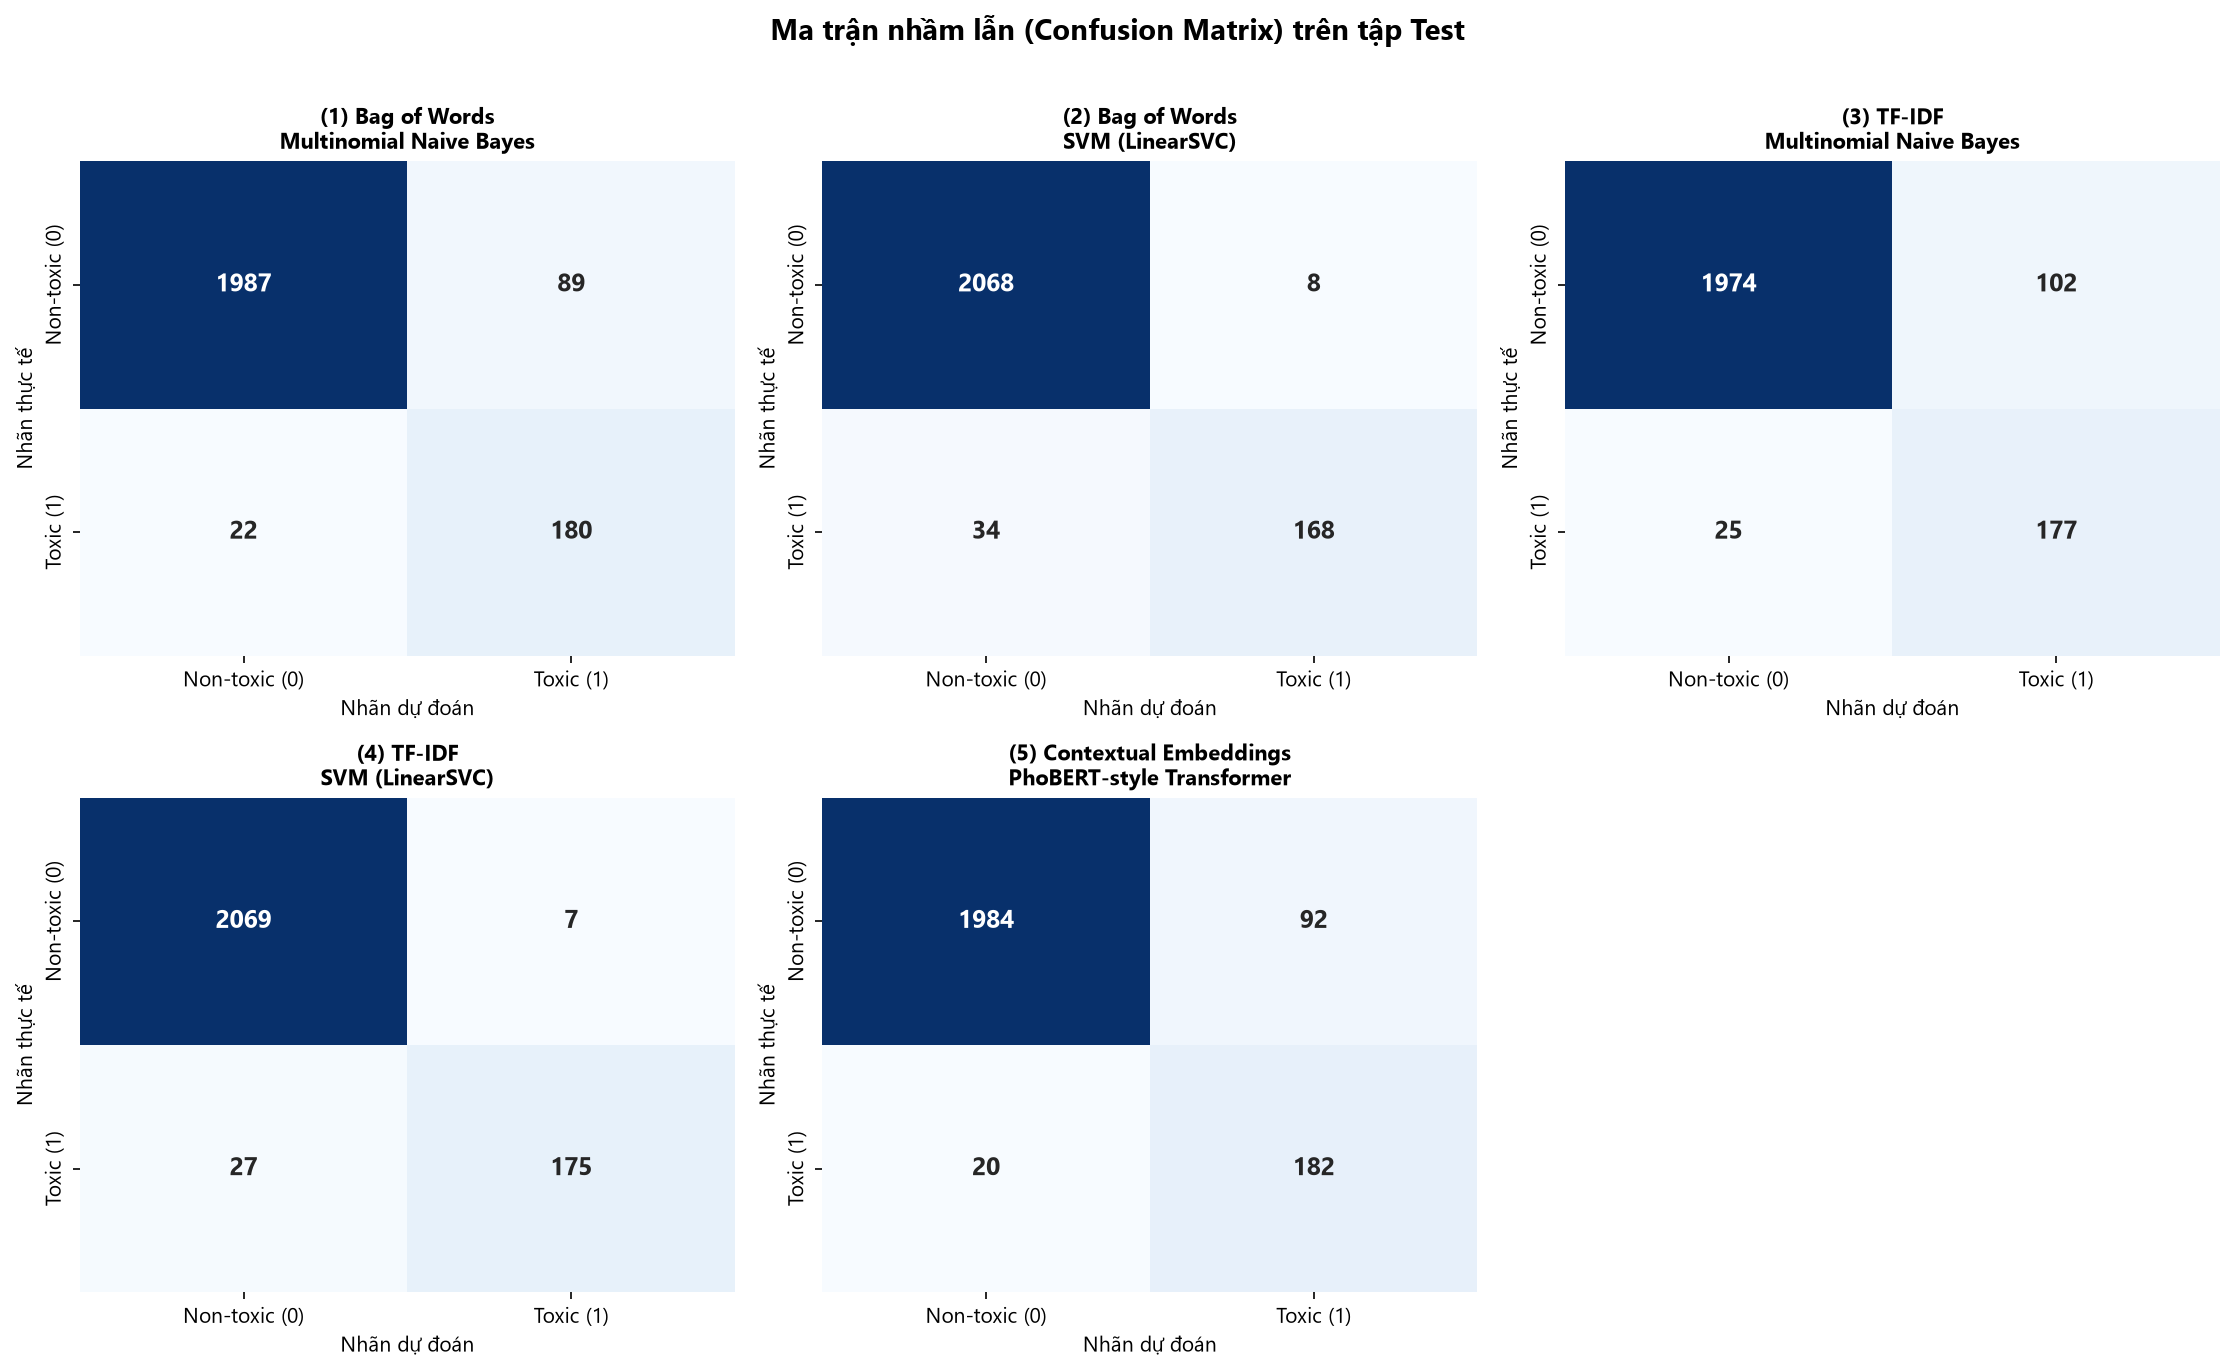

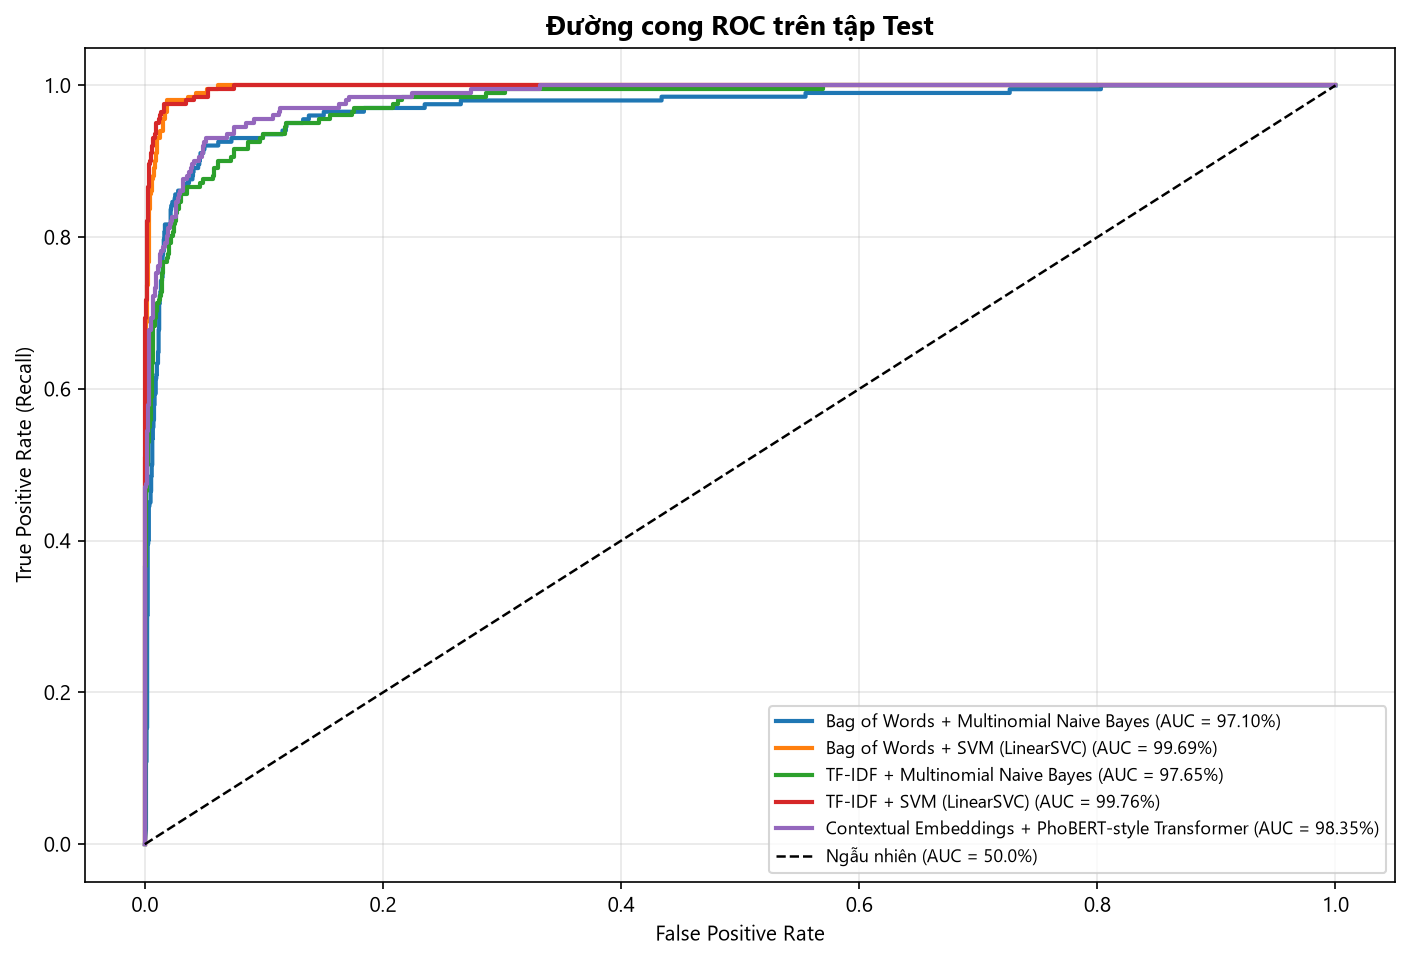

In [6]:
display(Image(filename='outputs/figures/03_model_comparison_metrics.png'))
display(Image(filename='outputs/figures/04_confusion_matrices_grid.png'))
display(Image(filename='outputs/figures/05_roc_curves.png'))

--- 
## Phân tích lỗi (Error Analysis) & Demo Dự đoán Trực tiếp (Live Inference)

In [7]:
import joblib

df_errors = pd.read_csv('outputs/error_analysis.csv')
print(f'Số lượng câu khó / biên giới (Borderline) có sự khác biệt dự đoán giữa các mô hình: {len(df_errors)}')
cols_err = [c for c in ['comment_id', 'category', 'product_name', 'source', 'raw_text', 'label'] if c in df_errors.columns]
display(df_errors[cols_err].head(10))

# Demo dự đoán câu mới với mô hình TF-IDF + SVM đã lưu
tfidf_ext = joblib.load('outputs/models/tfidf_extractor.pkl')
svm_model = joblib.load('outputs/models/best_traditional_svm_tfidf.pkl')

def predict_comment(text: str):
    clean = preprocessor.preprocess_text(text, for_transformer=False)
    vec = tfidf_ext.transform([clean])
    prob_toxic = svm_model.predict_proba(vec)[0, 1]
    pred_label = 'TOXIC (1)' if prob_toxic >= 0.5 else 'NON-TOXIC (0)'
    return pred_label, round(float(prob_toxic) * 100, 2), clean

test_sentences = [
    'Tivi Sony 65 inch hình ảnh sắc nét, nhân viên Điện Máy Xanh lắp đặt rất nhiệt tình chu đáo.',
    'Máy giặt mới mua 1 tuần đã kêu to và rò nước, gọi tổng đài bảo hành hẹn mãi chưa thấy ai xuống xử lý, quá thất vọng.',
    'Bọn đmx làm ăn l.ừ.a đ.ả.o mất dạy vkl, bán hàng phế thải còn thái độ bố láo với khách hàng 😡'
]

for sent in test_sentences:
    lbl, score, cleaned = predict_comment(sent)
    print(f'Bình luận : {sent}')
    print(f'Sau xử lý : {cleaned}')
    print(f'Dự đoán   : {lbl} (Xác suất Toxic: {score}%)')
    print('-' * 95)

Số lượng câu khó / biên giới (Borderline) có sự khác biệt dự đoán giữa các mô hình: 179


,comment_id,category,product_name,raw_text,label
0,DMX_REAL_07988,Máy lạnh,Sản phẩm ĐMX (Máy lạnh),"Thợ dmx đi gắn khoan lỗ xong không bít lại, cũ...",0
1,DMX_REAL_12298,Gia dụng,Sản phẩm ĐMX (Gia dụng),Xài vài tháng hư hết 1 bên. Bảo hành gần nữa t...,0
2,DMX_REAL_01335,Gia dụng,Sản phẩm DMX,Mua xài chưa được 1 tháng đã có dấu hiệu bong ...,1
3,DMX_REAL_05366,Máy lạnh,Máy lạnh LG Inverter 1.5 HP V13WIN1,Đợi giao hàng lâu quá quá à mua 1 tây hẹn 6 tâ...,0
4,DMX_REAL_03795,Gia dụng,Lò vi sóng Sharp R-205VN(S) 20 lít,"mua được hơn tháng quay thức ăn không nóng, gọ...",0
5,DMX_REAL_08099,Tivi,Sản phẩm ĐMX (Tivi),Rất tệ. Tivi mới mua chưa được 1 năm đang xem ...,0
6,DMX_REAL_08297,Máy giặt,Sản phẩm ĐMX (Máy giặt),"Làm ăn như cc, máy chạy ồn, rung lắc mạnh như ...",1
7,DMX_REAL_12465,Điện thoại,Sản phẩm ĐMX (Điện thoại),Kính gửi Bộ phận Chăm sóc Khách hàng Thế Giới ...,0
8,DMX_REAL_10183,Gia dụng,Sản phẩm ĐMX (Gia dụng),Tôi khuyên không ai nên mua vì hổ trợ cắt đá n...,0
9,DMX_REAL_00502,Máy lạnh,Sản phẩm DMX,Máy thì sau khi dùng 2 tuần chưa thấy vấn đề g...,0


Bình luận : Tivi Sony 65 inch hình ảnh sắc nét, nhân viên Điện Máy Xanh lắp đặt rất nhiệt tình chu đáo.
Sau xử lý : tivi sony inch hình_ảnh sắc nét nhân_viên điện_máy xanh lắp_đặt rất nhiệt_tình chu_đáo
Dự đoán   : NON-TOXIC (0) (Xác suất Toxic: 0.08%)
-----------------------------------------------------------------------------------------------
Bình luận : Máy giặt mới mua 1 tuần đã kêu to và rò nước, gọi tổng đài bảo hành hẹn mãi chưa thấy ai xuống xử lý, quá thất vọng.
Sau xử lý : máy_giặt mua kêu to rò nước gọi tổng_đài bảo_hành hẹn mãi chưa thấy ai xử_lý quá thất_vọng
Dự đoán   : NON-TOXIC (0) (Xác suất Toxic: 0.23%)
-----------------------------------------------------------------------------------------------
Bình luận : Bọn đmx làm ăn l.ừ.a đ.ả.o mất dạy vkl, bán hàng phế thải còn thái độ bố láo với khách hàng 😡
Sau xử lý : bọn điện_máy xanh làm_ăn lừa_đảo mất_dạy vãi cả lồn bán hàng phế_thải còn thái_độ bố_láo khách_hàng emoji_tuc_gian
Dự đoán   : TOXIC (1) (Xác suất Toxic: 1